### GPT Pretraining
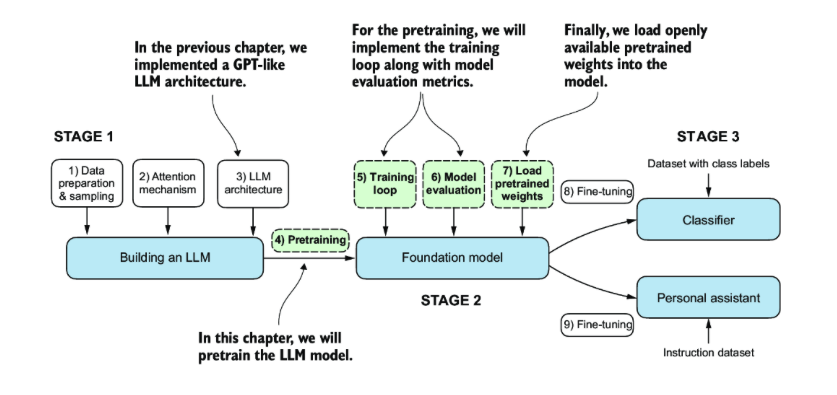

In [1]:
# Import the libraries
import re
import time
import urllib.request
from importlib.metadata import version
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from matplotlib import pyplot as plt
from GPT import GPTModel
from utils import generate_text_simple
from dataloader import create_dataloader_v1
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [2]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 128,    #1 Reduced the context size from 1024 to 256, so to train on laptop
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12, 
    "drop_rate": 0.1,       #2
    "qkv_bias": False
}
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(128, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features

- Controlling the context length is very important as it can reduce the memory usage while training locally

  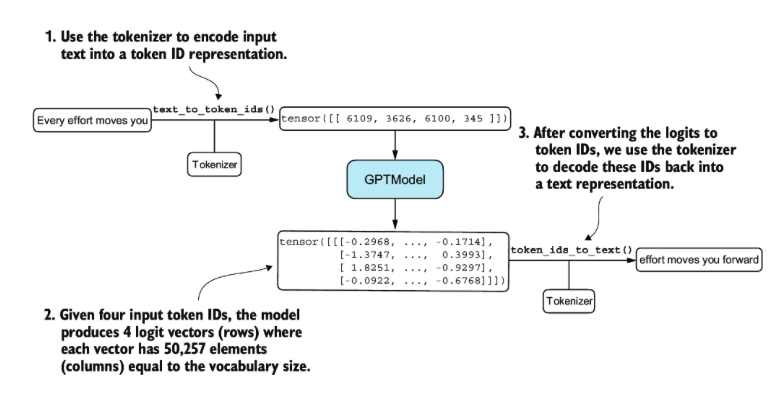

#### Utility functions for text to token id and vice versa

In [3]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)    #1
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)                #2
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you Spirits caves Feng lith cohorts Physical Position Wind Bars Vern


#### Loss Metrics
- How to assess quality of generated text? How far are generated token from target ones?
- Perplexity:
  - How well the model predicts a sample of text
  - What is the equally likely number of words the model is choosing from at given step when it needs to predict. Lesser it is, better the model.
  - It can provide a more interpretable way to understand the uncertainty of a model in predicting the next token in a sequence.
  - Higher the perplexity, model will be confused/uncertain as it needs to choose uniformly at random from larger pool of words. Can be thought as a branching factor
  - Perplexity == exponential(cross entropy loss)
  - Mathematically = 1/(P(s))^(1/N) = 1/(p(w_1)*p(w_2|w_1)*....*p(w_n|w_n-1.....w_1))^(1/N)
  - Basically inverse Nth square root of the sentence probability
  - This all are derived from the Cross entropy loss = Sum_N S_class y* log(p)
- The Cost of training a 7 billion parameter model on 2 trillion tokens >> 700 K usd or ~ 1 M usd
- For the current training, we will just utilize the small dataset.
- Cross Entropy loss is used for otimizing weights

In [4]:
file_path = "the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as file:
    text_data = file.read() 
    
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("Characters:", total_characters)
print("Tokens:", total_tokens)  

Characters: 20479
Tokens: 5145


#### Training process

In [5]:
# Data splitting process
train_ratio = 0.80
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [6]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=4,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)
val_loader = create_dataloader_v1(
    val_data,
    batch_size=4,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [7]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])

Validation loader:
torch.Size([4, 128]) torch.Size([4, 128])
torch.Size([4, 128]) torch.Size([4, 128])


In [8]:
## Loss calculation via cross entropy loss

def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)   # [batch, token, vocab]      #1 load data to GPU or CPU
    target_batch = target_batch.to(device)  # [batch, token]    
    logits = model(input_batch)
    ## CEL just takes the indices of the class and calculate the log(prob(that class))
    loss = torch.nn.functional.cross_entropy(  #[batch, token, vocab] >> [batch*token, vocab] for input batch
        logits.flatten(0, 1), target_batch.flatten() 
    )
    return loss

In [9]:
## Also calculate the total training and validation loss across all the batches

def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)     #1
    else:
        num_batches = min(num_batches, len(data_loader))   #2
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            total_loss += loss.item()    #3
        else:
            break
    return total_loss / num_batches    # Average the loss across number of batches

In [10]:
# Calculate the losses before training
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)  
model.to(device)   # load model to mps
with torch.no_grad():    # disable gradient tracking as we are just evaluting
    train_loss = calc_loss_loader(train_loader, model, device)    #3
    val_loss = calc_loss_loader(val_loader, model, device)
print("Training loss:", train_loss)
print("Validation loss:", val_loss) 

Training loss: 11.00720226764679
Validation loss: 11.03758955001831


#### LLM Training Process
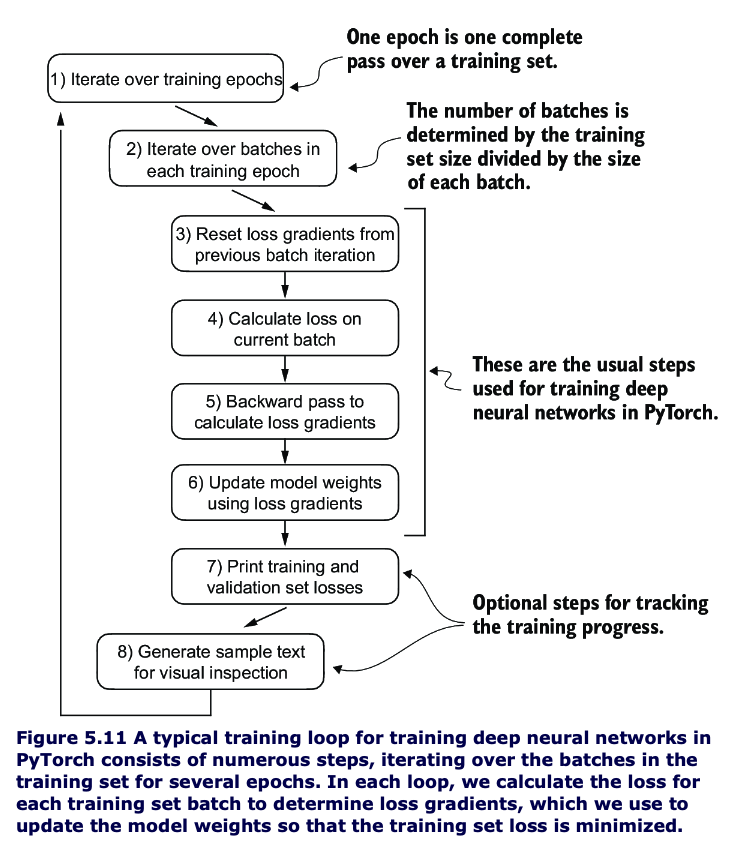

In [11]:
# Calculate the train and validation losses averaged over batches
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()  #1
    with torch.no_grad():                              #2
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )
    model.train()
    return train_loss, val_loss

In [12]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device) # token ids are loaded into device
    with torch.no_grad(): # generate 50 new tokens for testing
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))      #1
    model.train() # set the model to train mode for the next batch

In [13]:
def train_model_simple(model, train_loader, val_loader,
                       optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    train_losses, val_losses, track_tokens_seen = [], [], []    #1
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):    #2
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()   # Reset loss gradients to zero for each batch as they are accumulative
            
            loss = calc_loss_batch( # Cross entropy loss
                input_batch, target_batch, model, device
            )
            t0 = time.time()
            loss.backward()                     # Backpropogation to calculate the loss gradients
            
            t1 = time.time()
            optimizer.step()                    # Update the weights with the gradients
            
            t2 = time.time()

            if global_step == 1:
                print(f"loss calculation:{t1-t0:0.3f}, weight updates:{t2-t1}")
                
            tokens_seen += target_batch.numel() 
            global_step += 1 # counting epoch*batch

            if global_step % eval_freq == 0:    # Evaluates at certain frequency and not for every batch
                train_loss, val_loss = evaluate_model( # cumulative loss is calculated
                    model, train_loader, val_loader, device, eval_iter) # Alternatively training and validation loss can be calulated for each batch 
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}"
                )

        generate_and_print_sample(                      # Just print an example to see the evolution
            model, tokenizer, device, start_context
        )
    return train_losses, val_losses, track_tokens_seen

- Adam optimizers can use the learning rates adaptively. If the gradient is steep, high learning rates are used and slowed down if learning rates are slowed down.
- AdamW is a variant of Adam that improves the weight decay (regularization). This will prevent the overfitting of model by reducing model complexity and penalizes larger weights. This allow better generalization of the model.

In [14]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

optimizer = torch.optim.AdamW(
     model.parameters(),           # All the trainable parameters of the model
    lr=0.0004, weight_decay=0.1   # learning rate and regularization parameter
)
num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
) 

Ep 1 (Step 000000): Train loss 10.982, Val loss 10.981
loss calculation:0.012, weight updates:0.14392709732055664
Ep 1 (Step 000005): Train loss 9.444, Val loss 9.565
Every effort moves you the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
Ep 2 (Step 000010): Train loss 7.635, Val loss 8.047
Ep 2 (Step 000015): Train loss 6.498, Val loss 7.193
Every effort moves you the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
Ep 3 (Step 000020): Train loss 6.105, Val loss 7.008
Every effort moves you,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ep 4 (Step 000025): Train loss 6.077, Val loss 7.068
Ep 4 (Step 000030): Train loss 6.094, Val loss 7.168
Every effort moves you                           

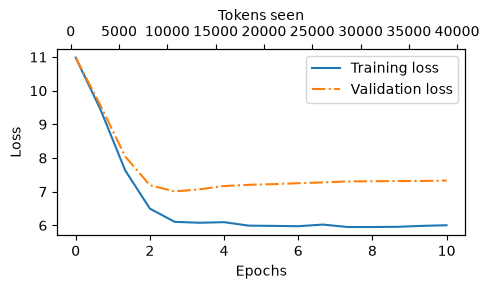

In [15]:
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
        epochs_seen, val_losses, linestyle="-.", label="Validation loss"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2 = ax1.twiny()                   #1
    ax2.plot(tokens_seen, train_losses, alpha=0)     #2
    ax2.set_xlabel("Tokens seen")
    fig.tight_layout()
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [16]:
generate_and_print_sample(model, tokenizer, device, "good morning")

good morning,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


#### Text generation strategies
- Greedy decoding: Sampling token with the highest probability in the vocabulary
- We can replace the highest probability with choosing the samples from a probability distribution.
- Basically replace the argmax with a multinomial sampling. After passing the tensor of probability scores, the function will generate a cumulative distribution function to create different possible ranges. If a randomly generated number falls in any of the categories, they will be classified.
- Basically this process can be repeated multiple times to see how a sample fall in different catagories in multiple trials which is the idea behind binomial sampling (similiar to a 6 side die in n number of trials)
  
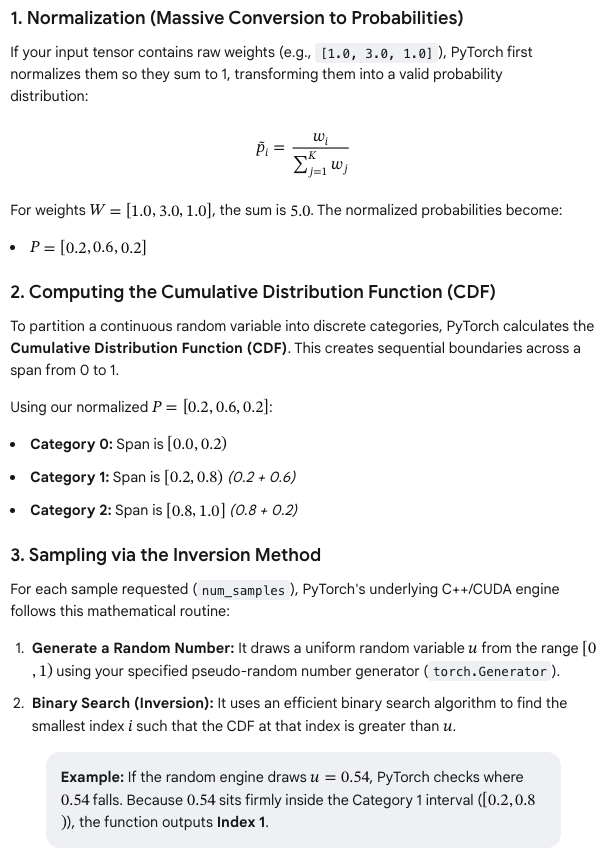

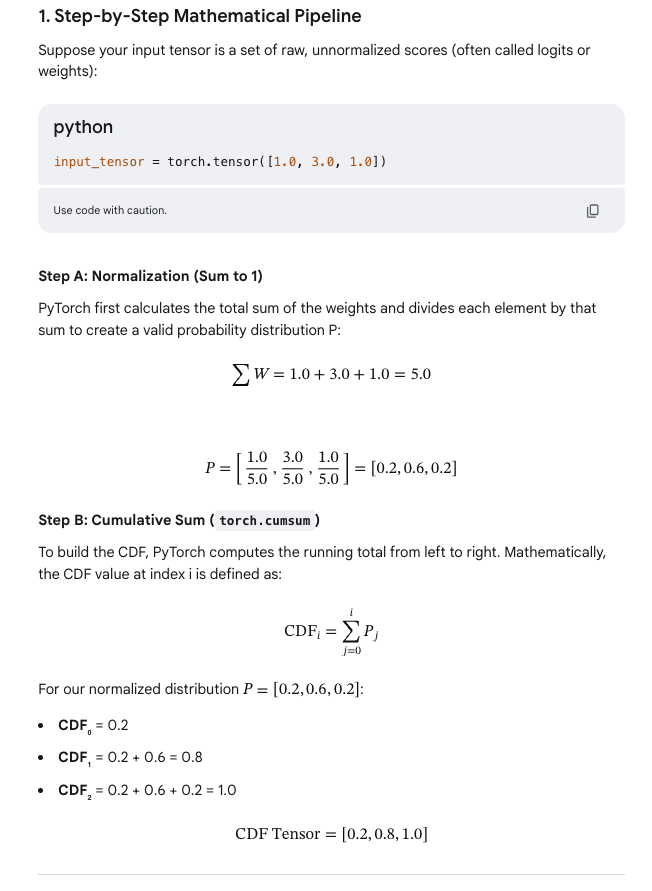


In [24]:
# Multinomial sampling
# Let's use an example vocab and logits values for this purpose
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 
inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)
probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.multinomial(probas, num_samples=5)
print(next_token_id)

tensor([7, 3, 0, 4, 8])


- Effectively there are two ways to diversify the new token generation process
  - Temperature scaling: Basically divide the logits by a scalar
    - Temperatures greater than 1 result in uniform token probs and temperatures less than 1 result in more sharper/peak probabilities
    - Temp > 1 results in uniform probabilities and diversify the output and results in exploring for creative paths than using the same likelihood token all the time. Downside is that, it can result in absurd or nonsensical text sometimes.
   - In top-k sampling, we only use the tokens with k top logits for the next token prediction process and exclude rest of them. This combined with temperature scaling can improve text generation results
   - This approach replaces all non-selected logits with negative infinity so that the probability goes to zero during softmax calculation and sum of selected probs becomes unity.

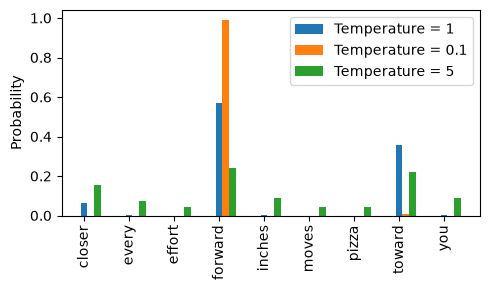

In [25]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

temperatures = [1, 0.1, 5]                                     #1
scaled_probas = [softmax_with_temperature(next_token_logits, T)
                for T in temperatures]
x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], 
                   bar_width, label=f'Temperature = {T}')
ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


In [28]:
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],    #1
    input=torch.tensor(float('-inf')),     #2
    other=next_token_logits     #3
)
print(new_logits)
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])
tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


In [29]:
# Modified text generation function:
def generate(model, idx, max_new_tokens, context_size,
             temperature=0.0, top_k=None, eos_id=None):
    for _ in range(max_new_tokens):            
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]
        if top_k is not None:                # Top k logic here
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float('-inf')).to(logits.device),
                logits
            )
        if temperature > 0.0:                  # temperaure scaling only to diversify the output
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
        else:    #4
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        if idx_next == eos_id:              # Disable generation if already end of sentence id is reached
            break
        idx = torch.cat((idx, idx_next), dim=1)
    return idx 

In [32]:
torch.manual_seed(123)
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you his had was to" had and a was the him him"'s the
